# Univariate LASSO Regression — Mini-Batch Gradient Descent\nFrom scratch using NumPy. No sklearn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)
X = np.arange(1, 51, dtype=float)
noise = np.random.normal(0, 3, size=len(X))
y = 2 * X + 1 + noise
train_size = int(0.8 * len(X))
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

In [2]:
def lasso_minibatch(X, y, learning_rate, lambda_, epochs, batch_size):
    w, b = 0.0, 0.0
    n = len(X)
    for epoch in range(epochs):
        indices = np.random.permutation(n)
        Xs, ys = X[indices], y[indices]
        for start in range(0, n, batch_size):
            Xb = Xs[start:start+batch_size]
            yb = ys[start:start+batch_size]
            m = len(Xb)
            error = (w * Xb + b) - yb
            dw = np.sum(error * Xb) / m
            db = np.sum(error) / m
            dw += lambda_ if w > 0 else (-lambda_ if w < 0 else 0)
            w -= learning_rate * dw
            b -= learning_rate * db
    return w, b
learning_rate = 0.001
lambda_ = 0.1
epochs = 2000
batch_size = 4
w, b = lasso_minibatch(X_train, y_train, learning_rate, lambda_, epochs, batch_size)
print('Weight:', w)
print('Bias:', b)

Weight: 1.9566062779321836
Bias: 1.6029358944743595


In [3]:
def predict(X): return w * X + b
y_train_pred = predict(X_train)
y_test_pred = predict(X_test)
train_mse = np.mean((y_train-y_train_pred)**2)
test_mse = np.mean((y_test-y_test_pred)**2)
train_cost = np.mean((y_train-y_train_pred)**2)/2 + lambda_*abs(w)
test_cost = np.mean((y_test-y_test_pred)**2)/2 + lambda_*abs(w)
print('Training MSE:', train_mse)
print('Testing MSE :', test_mse)
print('Training LASSO Cost:', train_cost)
print('Testing LASSO Cost :', test_cost)

Training MSE: 7.645457698551759
Testing MSE : 6.763760273381623
Training LASSO Cost: 4.018389477069098
Testing LASSO Cost : 3.57754076448403


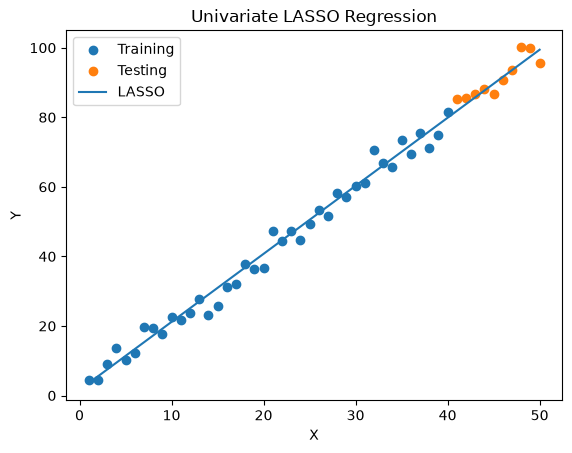

In [4]:
plt.scatter(X_train,y_train,label='Training')
plt.scatter(X_test,y_test,label='Testing')
plt.plot(X,predict(X),label='LASSO')
plt.xlabel('X'); plt.ylabel('Y'); plt.title('Univariate LASSO Regression')
plt.legend(); plt.show()